# Convolutional Neural Networks

## Project: Write an Algorithm for Landmark Classification

### A simple app

In this notebook we build a very simple app that uses our exported model.

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> Note how we are not importing anything from our source code (we do not use any module from the ``src`` directory). This is because the exported model, differently from the model weights, is a standalone serialization of our model and therefore it does not need anything else. You can ship that file to anybody, and as long as they can import ``torch``, they will be able to use your model. This is very important for releasing pytorch models to production.

### Test your app
Go to a search engine for images (like Google Images) and search for images of some of the landmarks, like the Eiffel Tower, the Golden Gate Bridge, Machu Picchu and so on. Save a few examples locally, then upload them to your app to see how your model behaves!

The app will show the top 5 classes that the model think are most relevant for the picture you have uploaded

In [1]:
from ipywidgets import VBox, Button, FileUpload, Output, Label
from PIL import Image
from IPython.display import display
import io
import numpy as np
import torchvision
import torchvision.transforms as T
import torch

# Decide which model you want to use among the ones exported
learn_inf = torch.jit.load("checkpoints/transfer_exported.pt")

def on_click_classify(change):

    # Load image that has been uploaded
    fn = io.BytesIO(btn_upload.data[-1])

    img = Image.open(fn)
    img.load()

    # Let's clear the previous output (if any)
    out_pl.clear_output()

    # Display the image
    with out_pl:

        ratio = img.size[0] / img.size[1]
        c = img.copy()
        c.thumbnail([ratio * 200, 200])
        display(c)

    # Transform to tensor
    timg = T.ToTensor()(img).unsqueeze_(0)

    # Calling the model
    softmax = learn_inf(timg).data.cpu().numpy().squeeze()

    # Get the indexes of the classes ordered by softmax
    # (larger first)
    idxs = np.argsort(softmax)[::-1]

    # Loop over the classes with the largest softmax
    for i in range(5):
        # Get softmax value
        p = softmax[idxs[i]]

        # Get class name
        landmark_name = learn_inf.class_names[idxs[i]]

        labels[i].value = f"{landmark_name} (prob: {p:.2f})"


# Putting back btn_upload to a widget for next cell
btn_upload = FileUpload()

btn_run = Button(description="Classify")
btn_run.on_click(on_click_classify)

labels = []
for _ in range(5):
    labels.append(Label())

out_pl = Output()
out_pl.clear_output()

wgs = [Label("Please upload a picture of a landmark"), btn_upload, btn_run, out_pl]
wgs.extend(labels)

VBox(wgs)


C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


## (optional) Standalone app or web app

You can run this notebook as a standalone app on your computer by following these steps:

1. Download this notebook in a directory on your machine
2. Download the model export (for example, ``checkpoints/transfer_exported.pt``) in a subdirectory called ``checkpoints`` within the directory where you save the app.ipynb notebook
3. Install voila if you don't have it already (``pip install voila``)
4. Run your app: ``voila app.ipynb --show_tracebacks=True``
5. Customize your notebook to make your app prettier and rerun voila

You can also deploy this app as a website using Binder: https://voila.readthedocs.io/en/stable/deploy.html#deployment-on-binder

# Create your submission archive

Now that you are done with your project, please run the following cell. It will generate a file containing all the code you have written, as well as the notebooks. Please submit that file to complete your project

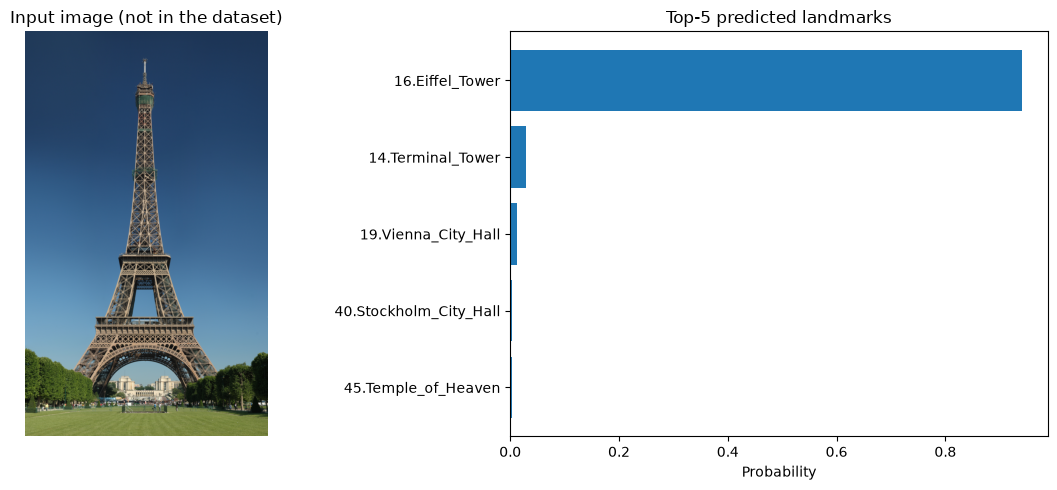

1. 16.Eiffel_Tower: 0.941
2. 14.Terminal_Tower: 0.029
3. 19.Vienna_City_Hall: 0.013
4. 40.Stockholm_City_Hall: 0.004
5. 45.Temple_of_Heaven: 0.003


In [2]:
# Demo: run the exported model on an image that is NOT part of the
# train/test dataset and show the top-5 predictions.
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image

sample_dir = "sample_images"
os.makedirs(sample_dir, exist_ok=True)
sample_path = os.path.join(sample_dir, "eiffel_tower.jpg")

if not os.path.exists(sample_path):
    url = (
        "https://upload.wikimedia.org/wikipedia/commons/8/85/"
        "Tour_Eiffel_Wikimedia_Commons_%28cropped%29.jpg"
    )
    urllib.request.urlretrieve(url, sample_path)


def predict_landmark(image_path, model, topk=5):
    """Return the top-k (class_name, probability) pairs for an image."""
    img = Image.open(image_path).convert("RGB")
    timg = T.ToTensor()(img).unsqueeze(0)
    with torch.no_grad():
        probs = model(timg).squeeze(0)
    top_probs, top_idxs = torch.topk(probs, topk)
    return [(model.class_names[i], float(p)) for p, i in zip(top_probs, top_idxs)]


predictions = predict_landmark(sample_path, learn_inf, topk=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(Image.open(sample_path))
axes[0].set_title("Input image (not in the dataset)")
axes[0].axis("off")

names = [name for name, _ in predictions][::-1]
probs = [p for _, p in predictions][::-1]
axes[1].barh(names, probs, color="tab:blue")
axes[1].set_xlabel("Probability")
axes[1].set_title("Top-5 predicted landmarks")
plt.tight_layout()
plt.show()

for rank, (name, prob) in enumerate(predictions, start=1):
    print(f"{rank}. {name}: {prob:.3f}")


In [3]:
!.\venv\Scripts\python.exe src/create_submit_pkg.py

executing: jupyter nbconvert --to html Project_Landmarks_Part1_CNNfromScratch__starter.ipynb
executing: jupyter nbconvert --to html Project_Landmarks_Part2_TransferLearning__starter.ipynb
executing: jupyter nbconvert --to html Project_Landmarks_Part3_App__starter.ipynb
Adding files to submission_2026-11-09T11h13m.tar.gz
src\create_submit_pkg.py
src\data.py
src\helpers.py
src\model.py
src\optimization.py
src\predictor.py
src\train.py
src\transfer.py
src\__init__.py
Project_Landmarks_Part1_CNNfromScratch__starter.ipynb
Project_Landmarks_Part2_TransferLearning__starter.ipynb
Project_Landmarks_Part3_App__starter.ipynb
Project_Landmarks_Part1_CNNfromScratch__starter.html
Project_Landmarks_Part2_TransferLearning__starter.html
Project_Landmarks_Part3_App__starter.html

----------------------------------------------------------------
Done. Please submit the file submission_2026-11-09T11h13m.tar.gz
----------------------------------------------------------------


[NbConvertApp] Converting notebook Project_Landmarks_Part1_CNNfromScratch__starter.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 1802915 bytes to Project_Landmarks_Part1_CNNfromScratch__starter.html
[NbConvertApp] Converting notebook Project_Landmarks_Part2_TransferLearning__starter.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 612599 bytes to Project_Landmarks_Part2_TransferLearning__starter.html
[NbConvertApp] Converting notebook Project_Landmarks_Part3_App__starter.ipynb to html
C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing th